In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error

In [34]:
df = pd.read_csv("uber.csv")

In [35]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB


In [37]:
df.shape

(200000, 9)

In [38]:
df.columns


Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='str')

In [39]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [40]:
df.drop(columns=['Unnamed: 0'], inplace=True)
df.head()

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [41]:
df.dropna(inplace=True)
df.isnull().sum()

key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [42]:
df.dtypes

key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [43]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df.dtypes

key                                  str
fare_amount                      float64
pickup_datetime      datetime64[us, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dtype: object

In [45]:
df.drop(columns=['key', 'pickup_datetime'], inplace=True)

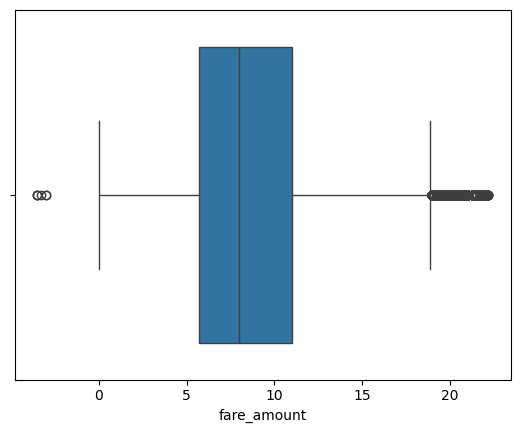

In [46]:
sns.boxplot(x=df["fare_amount"])
plt.show()

Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

df = df[(df["fare_amount"] >= Q1 - 1.5 * IQR) &
        (df["fare_amount"] <= Q3 + 1.5 * IQR)]

In [21]:
correlation = df.corr()

print(correlation)

                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000         -0.001505         0.004593   
pickup_longitude     -0.001505          1.000000        -0.808081   
pickup_latitude       0.004593         -0.808081         1.000000   
dropoff_longitude    -0.004605          0.833514        -0.763686   
dropoff_latitude      0.002338         -0.848146         0.678486   
passenger_count       0.015551         -0.000935        -0.001488   

                   dropoff_longitude  dropoff_latitude  passenger_count  
fare_amount                -0.004605          0.002338         0.015551  
pickup_longitude            0.833514         -0.848146        -0.000935  
pickup_latitude            -0.763686          0.678486        -0.001488  
dropoff_longitude           1.000000         -0.912350        -0.000027  
dropoff_latitude           -0.912350          1.000000        -0.000522  
passenger_count            -0.000027         -0.000522         1.000000 

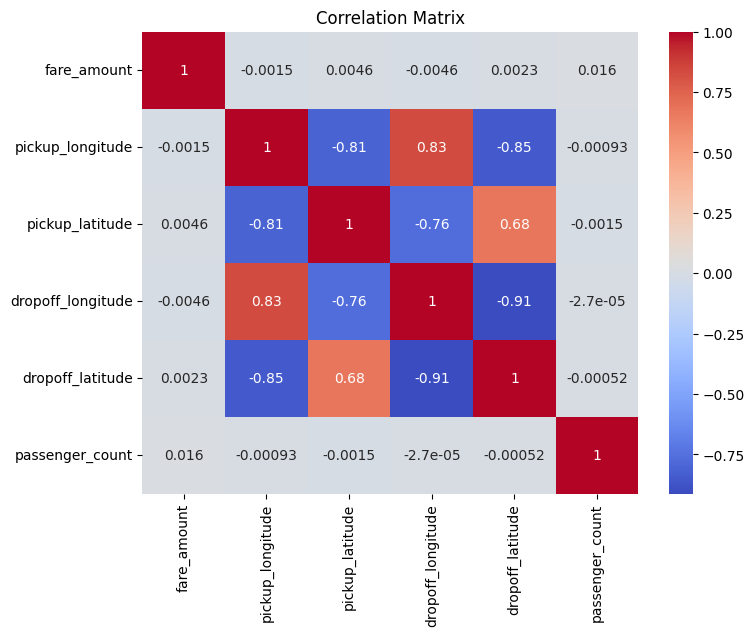

In [22]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [23]:
X = df.drop(columns=['fare_amount'])
y = df['fare_amount']

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [27]:
# 6. Linear Regression
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)

pred1 = lr.predict(X_test)

In [30]:
print("\nLinear Regression")
print("R2 Score:", r2_score(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))


Linear Regression
R2 Score: 0.0004036130856731601
RMSE: 3.637366657063469


In [31]:
from sklearn.ensemble import RandomForestRegressor

# 7. Random Forest Regression
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)

pred2 = rf.predict(X_test)

In [32]:
print("\nRandom Forest Regression")
print("R2 Score:", r2_score(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))


Random Forest Regression
R2 Score: 0.6821812491174886
RMSE: 2.050994523687445


In [33]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'R2 Score': [r2_lr, r2_rf],
    'RMSE': [rmse_lr, rmse_rf]
})

results

,Model,R2 Score,RMSE
0,Linear Regression,0.000083,4.136624
1,Random Forest Regression,0.705206,2.246070
